Knowing When the Model Doesn't Know
Notebook 01: Data exploration and baseline CNN
CSCI 6366 Neural Networks and Deep Learning, final project.

This notebook covers the initial stages of the project:

Load PneumoniaMNIST (main dataset) and BreastMNIST / OCTMNIST (out-of-distribution sets).
Explore the data: sizes, class balance, sample images.
Define a small CNN with dropout layers (needed later for MC Dropout).
Train the baseline model and check its accuracy.
Take a first look at softmax confidence on correct vs. wrong predictions.
Runs on Google Colab (Runtime > Change runtime type > GPU). A CPU also works, just slower.

In [1]:
# Install the MedMNIST package
!pip install -q medmnist

In [3]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
import torchvision.transforms as T
import matplotlib.pyplot as plt
import medmnist

from medmnist import PneumoniaMNIST, BreastMNIST, OCTMNIST

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 128
DATA_ROOT = "data"

import os
os.makedirs(DATA_ROOT, exist_ok=True)

print(f"Device: {DEVICE}")
print(f"MedMNIST version: {medmnist.__version__}")

Device: cuda
MedMNIST version: 3.0.2


1. Load the datasets
All images are 28x28 grayscale. We scale pixels to [0, 1] and then normalize to roughly [-1, 1].

Dataset	Image type	Role
PneumoniaMNIST	Chest X-ray (normal vs. pneumonia)	Train / validate / test
BreastMNIST	Breast ultrasound	Out-of-distribution (never trained on)
OCTMNIST	Retinal OCT scan	Out-of-distribution (never trained on)


In [4]:

# Define image transformations
transform = T.Compose([
    T.ToTensor(),                       # Convert pixel values from [0, 255] to [0, 1]
    T.Normalize(mean=[0.5], std=[0.5])  # Normalize pixel values to [-1, 1]
])


# Function to load MedMNIST dataset splits
def load_split(dataset_class, split):
    return dataset_class(
        split=split,
        transform=transform,
        download=True,
        root=DATA_ROOT
    )


# Load PneumoniaMNIST datasets
print("Loading PneumoniaMNIST datasets...")

train_set = load_split(PneumoniaMNIST, "train")
val_set = load_split(PneumoniaMNIST, "val")
test_set = load_split(PneumoniaMNIST, "test")


# Load out-of-distribution datasets
print("\nLoading out-of-distribution datasets...")

ood_breast = load_split(BreastMNIST, "test")
ood_oct = load_split(OCTMNIST, "test")


# Create DataLoaders
train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)


# Define class labels
CLASS_NAMES = ["normal", "pneumonia"]


# Display dataset information
print("\nDataset loading completed successfully!")
print(f"Training samples:   {len(train_set)}")
print(f"Validation samples: {len(val_set)}")
print(f"Testing samples:    {len(test_set)}")
print(f"BreastMNIST OOD:    {len(ood_breast)}")
print(f"OCTMNIST OOD:       {len(ood_oct)}")


Loading PneumoniaMNIST datasets...


100%|██████████| 4.17M/4.17M [00:02<00:00, 1.54MB/s]



Loading out-of-distribution datasets...


100%|██████████| 560k/560k [00:01<00:00, 439kB/s]
100%|██████████| 54.9M/54.9M [00:28<00:00, 1.93MB/s]



Dataset loading completed successfully!
Training samples:   4708
Validation samples: 524
Testing samples:    624
BreastMNIST OOD:    156
OCTMNIST OOD:       1000


2. Explore the data

In [5]:

# Function to calculate class distribution
def class_counts(dataset):
    labels = np.asarray(dataset.labels).flatten()

    return {
        name: int(np.sum(labels == i))
        for i, name in enumerate(CLASS_NAMES)
    }


# Display class distribution across PneumoniaMNIST splits
print("=" * 65)
print("PNEUMONIAMNIST CLASS DISTRIBUTION")
print("=" * 65)

header = (
    f"{'Split':<12}"
    f"{'Total':>10}"
    f"{'Normal':>10}"
    f"{'Pneumonia':>12}"
    f"{'% Pneumonia':>15}"
)

print(header)
print("-" * 65)

for split_name, dataset in [
    ("Training", train_set),
    ("Validation", val_set),
    ("Testing", test_set)
]:
    counts = class_counts(dataset)
    total = len(dataset)

    if total == 0:
        print(f"{split_name:<12} Dataset is empty!")
        continue

    pneumonia_percentage = (
        counts["pneumonia"] / total
    ) * 100

    print(
        f"{split_name:<12}"
        f"{total:>10}"
        f"{counts['normal']:>10}"
        f"{counts['pneumonia']:>12}"
        f"{pneumonia_percentage:>14.1f}%"
    )

print("\n" + "=" * 65)
print("OUT-OF-DISTRIBUTION DATASET SUMMARY")
print("=" * 65)

print(f"BreastMNIST test images: {len(ood_breast)}")
print(f"OCTMNIST test images:    {len(ood_oct)}")


PNEUMONIAMNIST CLASS DISTRIBUTION
Split            Total    Normal   Pneumonia    % Pneumonia
-----------------------------------------------------------------
Training          4708      1214        3494          74.2%
Validation         524       135         389          74.2%
Testing            624       234         390          62.5%

OUT-OF-DISTRIBUTION DATASET SUMMARY
BreastMNIST test images: 156
OCTMNIST test images:    1000


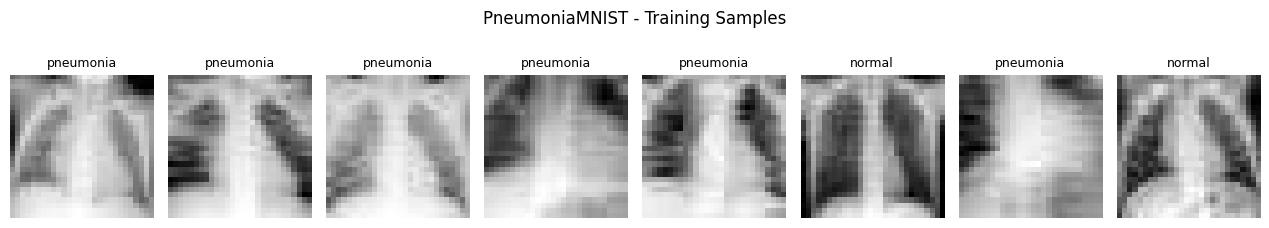

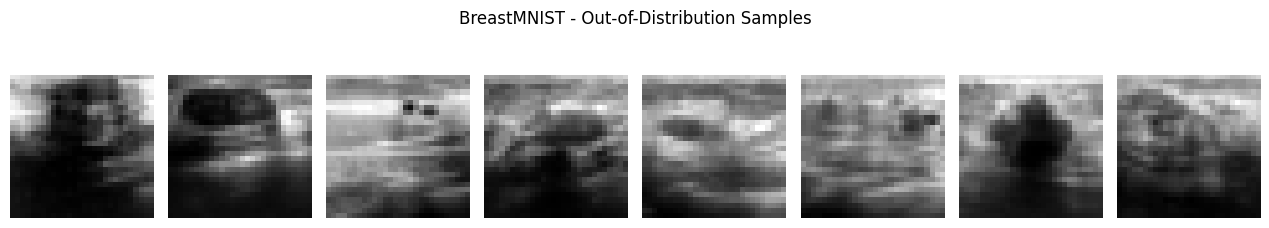

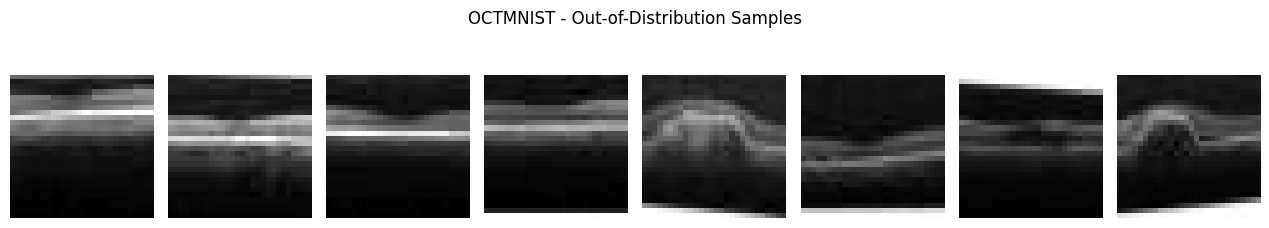

In [6]:

# Function to visualize sample images from a dataset
def show_examples(dataset, title, n=8, label_names=None):

    fig, axes = plt.subplots(1, n, figsize=(n * 1.6, 2.5))

    for ax, idx in zip(axes, range(min(n, len(dataset)))):

        img, label = dataset[idx]

        # Convert tensor to NumPy for visualization
        img = img.squeeze(0).numpy()

        ax.imshow(img, cmap="gray")

        if label_names is not None:
            label_idx = int(np.asarray(label).item())
            ax.set_title(label_names[label_idx], fontsize=9)

        ax.axis("off")

    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


# Visualize PneumoniaMNIST training samples
show_examples(
    train_set,
    "PneumoniaMNIST - Training Samples",
    n=8,
    label_names=CLASS_NAMES
)

# Visualize BreastMNIST OOD samples
show_examples(
    ood_breast,
    "BreastMNIST - Out-of-Distribution Samples",
    n=8
)

# Visualize OCTMNIST OOD samples
show_examples(
    ood_oct,
    "OCTMNIST - Out-of-Distribution Samples",
    n=8
)


3. Model: a small CNN with dropout
Standard architectures like ResNet do not include dropout layers. We build our own small CNN so dropout sits after every convolution block and before the classifier. During normal testing, dropout is turned off. For Monte Carlo Dropout (next notebook) we keep it on at test time and run each image many times; the spread of the predictions is the uncertainty.

In [7]:

# Define the CNN architecture with Dropout
class DropoutCNN(nn.Module):
    """
    CNN with three convolutional blocks and dropout layers.

    Each convolutional block consists of:
    Convolution -> Batch Normalization -> ReLU ->
    Max Pooling -> Dropout

    Dropout is included to support Monte Carlo Dropout
    during uncertainty estimation.
    """

    def __init__(self, num_classes=2, dropout_p=0.3):
        super(DropoutCNN, self).__init__()

        # Define a reusable convolutional block
        def conv_block(in_channels, out_channels):
            return nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=3,
                    padding=1
                ),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
                nn.Dropout(p=dropout_p)
            )

        # Feature extraction layers
        self.features = nn.Sequential(
            conv_block(1, 32),     # 28x28 -> 14x14
            conv_block(32, 64),    # 14x14 -> 7x7
            conv_block(64, 128)    # 7x7 -> 3x3
        )

        # Classification layers
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Initialize the model
model = DropoutCNN(
    num_classes=len(CLASS_NAMES),
    dropout_p=0.3
).to(DEVICE)


# Display model architecture
print("CNN Architecture:")
print(model)


# Calculate trainable parameters
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"\nTrainable parameters: {total_params:,}")


# Verify model input and output dimensions
dummy_input = torch.randn(1, 1, 28, 28).to(DEVICE)

model.eval()

with torch.no_grad():
    dummy_output = model(dummy_input)

print("\nModel verification:")
print(f"Input shape:  {tuple(dummy_input.shape)}")
print(f"Output shape: {tuple(dummy_output.shape)}")

assert dummy_output.shape == (1, len(CLASS_NAMES)), \
    "Model output dimensions are incorrect!"

print("CNN model initialized and verified successfully!")


CNN Architecture:
DropoutCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Dropout(p=0.3, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Dropout(p=0.3, inplace=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(ke

4. Train the baseline model

In [8]:

# Training configuration
NUM_EPOCHS = 15
LEARNING_RATE = 1e-3

# Define optimizer and loss function
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

loss_fn = nn.CrossEntropyLoss()


# Function to run one training or validation epoch
def run_epoch(model, loader, train=False):

    # Set model mode
    model.train() if train else model.eval()

    total_loss = 0.0
    correct = 0
    count = 0

    # Enable gradients only during training
    with torch.set_grad_enabled(train):

        for images, labels in loader:

            # Move images and labels to the selected device
            images = images.to(DEVICE)
            labels = labels.reshape(-1).long().to(DEVICE)

            # Forward pass
            logits = model(images)

            # Calculate loss
            loss = loss_fn(logits, labels)

            if train:
                # Backpropagation
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

            # Update statistics
            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            count += batch_size

    if count == 0:
        raise ValueError("The data loader is empty.")

    average_loss = total_loss / count
    accuracy = correct / count

    return average_loss, accuracy


# Store training history
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}


# Track the best validation model
best_val_acc = -1.0
best_state = None


# Training loop
print("Starting baseline CNN training...\n")

for epoch in range(1, NUM_EPOCHS + 1):

    # Training phase
    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        train=True
    )

    # Validation phase
    val_loss, val_acc = run_epoch(
        model,
        val_loader,
        train=False
    )

    # Record metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # Save weights when validation accuracy improves
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    # Display epoch results
    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )


# Restore the best model weights
if best_state is None:
    raise RuntimeError("Training failed: No valid model checkpoint was created.")

model.load_state_dict(best_state)
model.to(DEVICE)

print("\n" + "=" * 65)
print("TRAINING COMPLETED")
print("=" * 65)

print(f"Best validation accuracy: {best_val_acc:.4f}")
print("Best model weights successfully restored.")


Starting baseline CNN training...

Epoch 01/15 | Train Loss: 0.2360 | Train Acc: 0.8963 | Val Loss: 2.0325 | Val Acc: 0.7424
Epoch 02/15 | Train Loss: 0.1385 | Train Acc: 0.9469 | Val Loss: 0.1284 | Val Acc: 0.9504
Epoch 03/15 | Train Loss: 0.1198 | Train Acc: 0.9535 | Val Loss: 0.2216 | Val Acc: 0.9122
Epoch 04/15 | Train Loss: 0.1224 | Train Acc: 0.9518 | Val Loss: 0.0941 | Val Acc: 0.9637
Epoch 05/15 | Train Loss: 0.1080 | Train Acc: 0.9560 | Val Loss: 0.0982 | Val Acc: 0.9580
Epoch 06/15 | Train Loss: 0.0938 | Train Acc: 0.9622 | Val Loss: 0.1113 | Val Acc: 0.9561
Epoch 07/15 | Train Loss: 0.0923 | Train Acc: 0.9647 | Val Loss: 0.1263 | Val Acc: 0.9561
Epoch 08/15 | Train Loss: 0.0961 | Train Acc: 0.9654 | Val Loss: 0.0791 | Val Acc: 0.9676
Epoch 09/15 | Train Loss: 0.0967 | Train Acc: 0.9647 | Val Loss: 0.1234 | Val Acc: 0.9523
Epoch 10/15 | Train Loss: 0.0879 | Train Acc: 0.9647 | Val Loss: 0.0767 | Val Acc: 0.9656
Epoch 11/15 | Train Loss: 0.0788 | Train Acc: 0.9713 | Val Loss: 

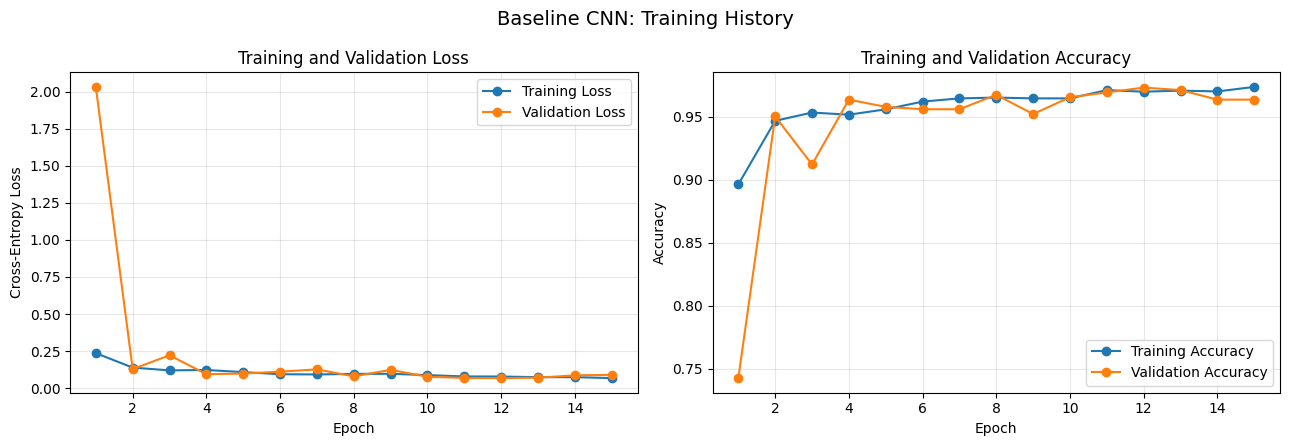

In [9]:

# Generate training history plots

epochs = range(1, NUM_EPOCHS + 1)

fig, (ax_loss, ax_acc) = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

# Loss plot
ax_loss.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

ax_loss.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

ax_loss.set_title("Training and Validation Loss")
ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Cross-Entropy Loss")
ax_loss.legend()
ax_loss.grid(alpha=0.3)

# Accuracy plot
ax_acc.plot(
    epochs,
    history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

ax_acc.plot(
    epochs,
    history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

ax_acc.set_title("Training and Validation Accuracy")
ax_acc.set_xlabel("Epoch")
ax_acc.set_ylabel("Accuracy")
ax_acc.legend()
ax_acc.grid(alpha=0.3)

plt.suptitle(
    "Baseline CNN: Training History",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [10]:

# Evaluate the trained model on the test dataset

@torch.no_grad()
def predict_softmax(model, loader):

    model.eval()

    all_probs = []
    all_labels = []

    for images, labels in loader:

        images = images.to(DEVICE)

        # Generate model predictions
        logits = model(images)

        # Convert logits into probabilities
        probabilities = F.softmax(logits, dim=1)

        all_probs.append(probabilities.cpu())
        all_labels.append(labels.reshape(-1).cpu())

    return (
        torch.cat(all_probs).numpy(),
        torch.cat(all_labels).numpy()
    )


# Obtain test predictions
test_probs, test_labels = predict_softmax(model, test_loader)

# Predicted classes and confidence scores
test_preds = test_probs.argmax(axis=1)
confidence = test_probs.max(axis=1)

# Identify correct and incorrect predictions
is_correct = test_preds == test_labels

# Calculate overall test accuracy
test_accuracy = is_correct.mean()

print("=" * 60)
print("BASELINE CNN - TEST RESULTS")
print("=" * 60)

print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

# Calculate class-wise recall
print("\nClass-wise Recall:")

for i, class_name in enumerate(CLASS_NAMES):

    mask = test_labels == i

    if mask.sum() == 0:
        print(f"{class_name}: No samples available")
        continue

    recall = (test_preds[mask] == i).mean()

    print(
        f"{class_name:<12}: {recall:.4f} "
        f"({int(mask.sum())} images)"
    )


# Compare confidence on correct and incorrect predictions
print("\nSoftmax Confidence Analysis:")

if is_correct.any():
    print(
        f"Mean confidence when correct: "
        f"{confidence[is_correct].mean():.4f}"
    )
else:
    print("No correct predictions available.")

if (~is_correct).any():
    print(
        f"Mean confidence when wrong:   "
        f"{confidence[~is_correct].mean():.4f}"
    )
else:
    print("No incorrect predictions available.")

print("=" * 60)


BASELINE CNN - TEST RESULTS
Test Accuracy: 0.8301 (83.01%)

Class-wise Recall:
normal      : 0.5556 (234 images)
pneumonia   : 0.9949 (390 images)

Softmax Confidence Analysis:
Mean confidence when correct: 0.9680
Mean confidence when wrong:   0.8639


Confusion Matrix:
[[130 104]
 [  2 388]]

Classification Report:
              precision    recall  f1-score   support

      normal     0.9848    0.5556    0.7104       234
   pneumonia     0.7886    0.9949    0.8798       390

    accuracy                         0.8301       624
   macro avg     0.8867    0.7752    0.7951       624
weighted avg     0.8622    0.8301    0.8163       624



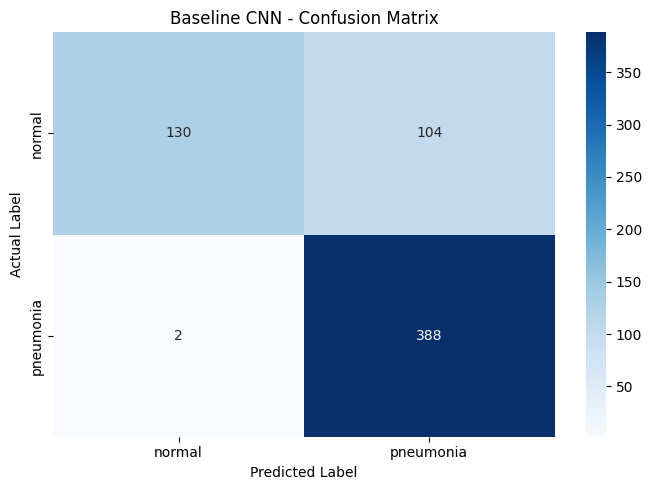

In [11]:

# Generate confusion matrix
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

cm = confusion_matrix(
    test_labels,
    test_preds,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_preds,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Baseline CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()


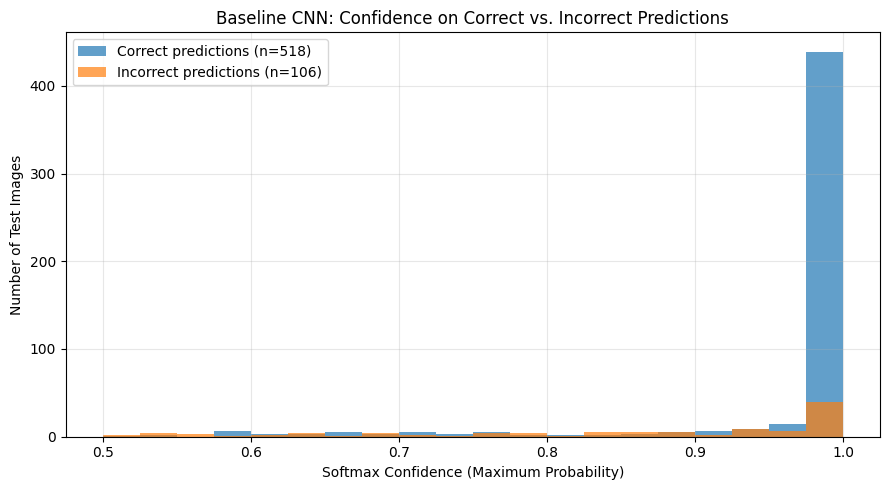

Confidence Summary
---------------------------------------------
Correct predictions:   0.9680
Incorrect predictions: 0.8639
Number of correct predictions:   518
Number of incorrect predictions: 106


In [12]:

# Compare softmax confidence for correct and incorrect predictions

bins = np.linspace(0.5, 1.0, 21)

correct_confidence = confidence[is_correct]
incorrect_confidence = confidence[~is_correct]

plt.figure(figsize=(9, 5))

plt.hist(
    correct_confidence,
    bins=bins,
    alpha=0.7,
    label=f"Correct predictions (n={len(correct_confidence)})"
)

plt.hist(
    incorrect_confidence,
    bins=bins,
    alpha=0.7,
    label=f"Incorrect predictions (n={len(incorrect_confidence)})"
)

plt.xlabel("Softmax Confidence (Maximum Probability)")
plt.ylabel("Number of Test Images")

plt.title(
    "Baseline CNN: Confidence on Correct vs. Incorrect Predictions"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Display confidence statistics
print("Confidence Summary")
print("-" * 45)

print(
    f"Correct predictions:   "
    f"{correct_confidence.mean():.4f}"
)

print(
    f"Incorrect predictions: "
    f"{incorrect_confidence.mean():.4f}"
)

print(
    f"Number of correct predictions:   "
    f"{len(correct_confidence)}"
)

print(
    f"Number of incorrect predictions: "
    f"{len(incorrect_confidence)}"
)


Evaluating OOD confidence...

BASELINE CNN - OOD CONFIDENCE ANALYSIS
Dataset                                    Mean Confidence
-----------------------------------------------------------------
PneumoniaMNIST (Familiar)                          0.9503
BreastMNIST (OOD)                                  0.9132
OCTMNIST (OOD)                                     0.9714


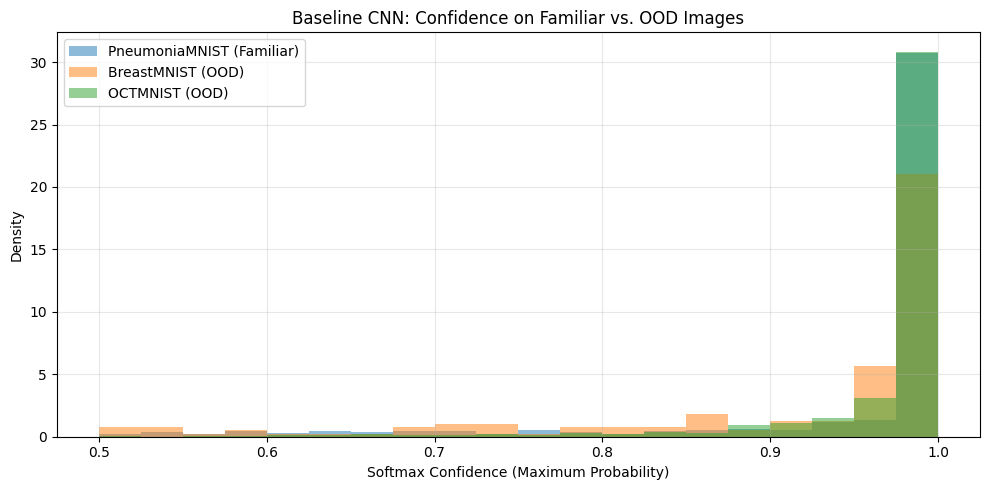

In [13]:

# Evaluate confidence on out-of-distribution datasets

# Create DataLoaders for OOD datasets
ood_breast_loader = DataLoader(
    ood_breast,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

ood_oct_loader = DataLoader(
    ood_oct,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)


# Function to calculate maximum softmax confidence
def ood_confidence(loader):

    probs, labels = predict_softmax(model, loader)

    return probs.max(axis=1)


# Calculate confidence for each dataset
print("Evaluating OOD confidence...")

conf_breast = ood_confidence(ood_breast_loader)
conf_oct = ood_confidence(ood_oct_loader)


# Display confidence statistics
print("\n" + "=" * 65)
print("BASELINE CNN - OOD CONFIDENCE ANALYSIS")
print("=" * 65)

print(f"{'Dataset':<38}{'Mean Confidence':>20}")
print("-" * 65)

print(
    f"{'PneumoniaMNIST (Familiar)':<38}"
    f"{confidence.mean():>19.4f}"
)

print(
    f"{'BreastMNIST (OOD)':<38}"
    f"{conf_breast.mean():>19.4f}"
)

print(
    f"{'OCTMNIST (OOD)':<38}"
    f"{conf_oct.mean():>19.4f}"
)

print("=" * 65)


# Visualize confidence distributions
plt.figure(figsize=(10, 5))

for values, label in [
    (confidence, "PneumoniaMNIST (Familiar)"),
    (conf_breast, "BreastMNIST (OOD)"),
    (conf_oct, "OCTMNIST (OOD)")
]:

    plt.hist(
        values,
        bins=np.linspace(0.5, 1.0, 21),
        alpha=0.5,
        density=True,
        label=label
    )


plt.xlabel("Softmax Confidence (Maximum Probability)")
plt.ylabel("Density")

plt.title(
    "Baseline CNN: Confidence on Familiar vs. OOD Images"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


5. Save the baseline model

In [14]:

# Save the best baseline CNN checkpoint

import os

# Create checkpoint directory
CHECKPOINT_DIR = "checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Define checkpoint path
CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "baseline_seed42.pt"
)

# Save model parameters and training configuration
checkpoint = {
    "model_state_dict": model.state_dict(),
    "model_architecture": "DropoutCNN",
    "num_classes": len(CLASS_NAMES),
    "dropout_p": 0.3,
    "best_val_accuracy": best_val_acc,
    "num_epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "seed": SEED,
    "class_names": CLASS_NAMES
}

torch.save(checkpoint, CHECKPOINT_PATH)

# Verify that the checkpoint exists
if os.path.exists(CHECKPOINT_PATH):

    file_size = os.path.getsize(CHECKPOINT_PATH) / (1024 ** 2)

    print("Baseline checkpoint saved successfully!")
    print(f"Location: {CHECKPOINT_PATH}")
    print(f"File size: {file_size:.2f} MB")

else:
    raise FileNotFoundError("Checkpoint was not saved.")


Baseline checkpoint saved successfully!
Location: checkpoints/baseline_seed42.pt
File size: 0.93 MB


In [15]:

# Verify saved checkpoint

loaded_checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

verification_model = DropoutCNN(
    num_classes=loaded_checkpoint["num_classes"],
    dropout_p=loaded_checkpoint["dropout_p"]
).to(DEVICE)

verification_model.load_state_dict(
    loaded_checkpoint["model_state_dict"]
)

verification_model.eval()

print("Checkpoint loaded successfully!")
print(f"Architecture: {loaded_checkpoint['model_architecture']}")
print(f"Best validation accuracy: {loaded_checkpoint['best_val_accuracy']:.4f}")
print("Model weights verified successfully.")


Checkpoint loaded successfully!
Architecture: DropoutCNN
Best validation accuracy: 0.9733
Model weights verified successfully.


In [16]:
from google.colab import files

files.download("checkpoints/baseline_seed42.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>